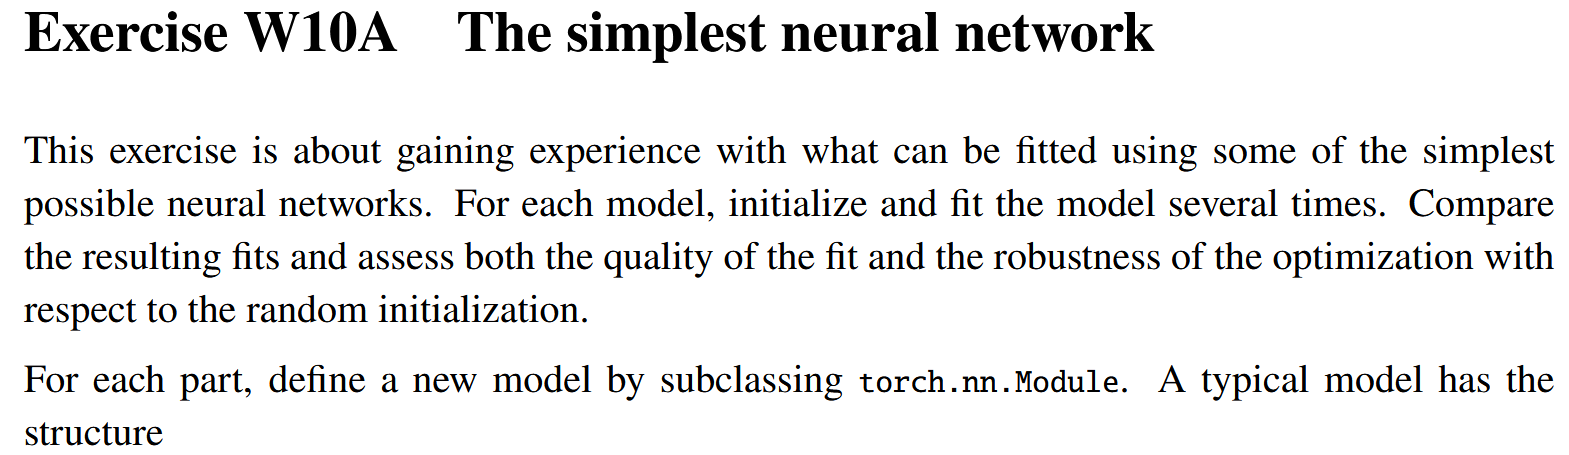
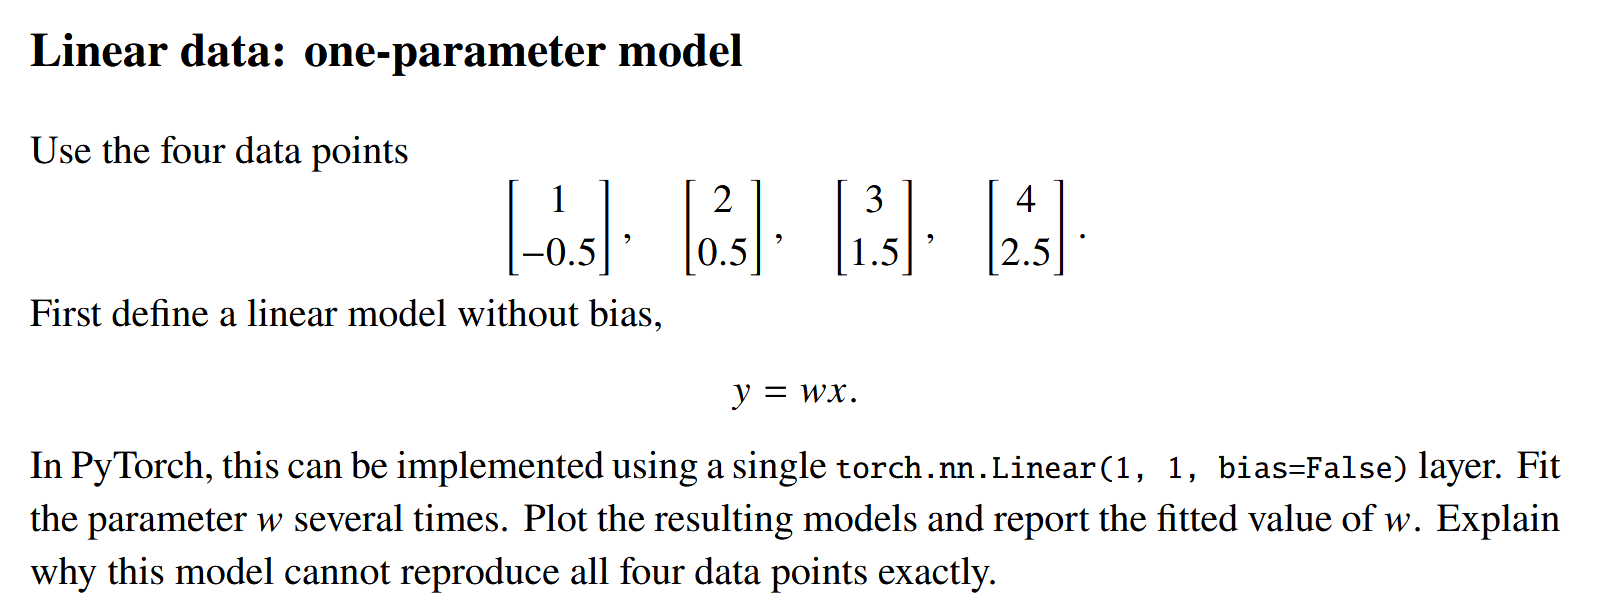

Fitted value of w: 0.5000


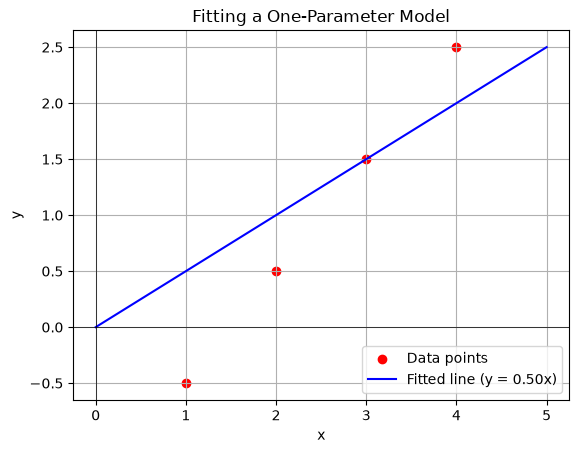

In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

class LinearModel(nn.Module):
    def __init__(self, *args, bias=True, **kwargs):
        super().__init__(*args, **kwargs)
        self.layer1 = nn.Linear(1, 1, bias=bias)

    def forward(self, x):
        x = x.view(-1, 1)
        x = self.layer1(x)
        return x.flatten()

    def fit(self, xs, ys, epochs=500, lr=0.1,
            lossFunction=nn.MSELoss, optimizer=optim.Adam):
        
        self.lossFunc = lossFunction()
        self.optimizer = optimizer(self.parameters(), lr=lr)

        for _ in range(epochs):
            self.optimizer.zero_grad()
            pred = self(xs)
            loss = self.lossFunc(pred, ys)
            loss.backward()
            self.optimizer.step()

        # Wack way -_-
        return tuple(map(lambda p: p.item(), self.parameters()))

xs = torch.tensor([ 1.0, 2.0, 3.0, 4.0])
ys = torch.tensor([-0.5, 0.5, 1.5, 2.5])

model = LinearModel(bias=False)
fitted_w = model.fit(xs, ys)[0]

print(f"Fitted value of w: {fitted_w:.4f}")

# Plotting the resulting model
plt.scatter(xs.numpy(), ys.numpy(), color='red', label='Data points')

x_vals = torch.linspace(0, 5, 100).view(-1, 1)

plt.plot(x_vals.numpy(), model(x_vals).detach().numpy(), color='blue', label=f'Fitted line (y = {fitted_w:.2f}x)')

plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend()
plt.grid()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Fitting a One-Parameter Model')
plt.show()

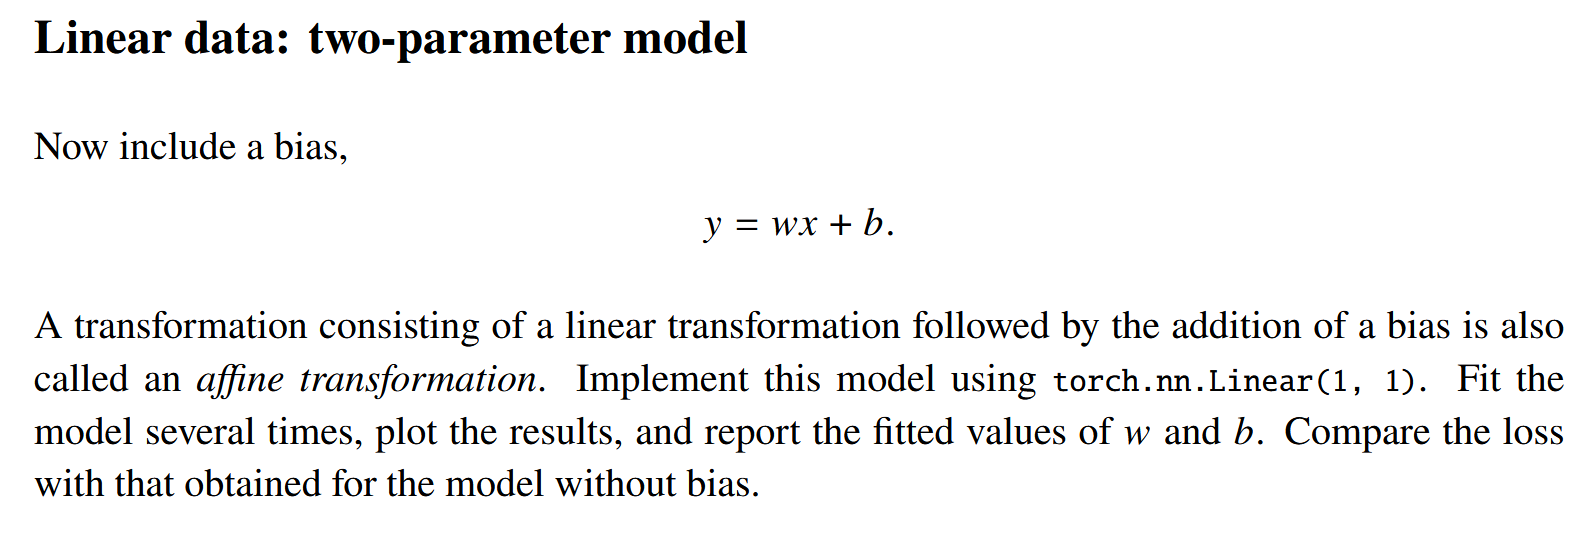

Fitted parameters: w = 1.0000, b = -1.5000


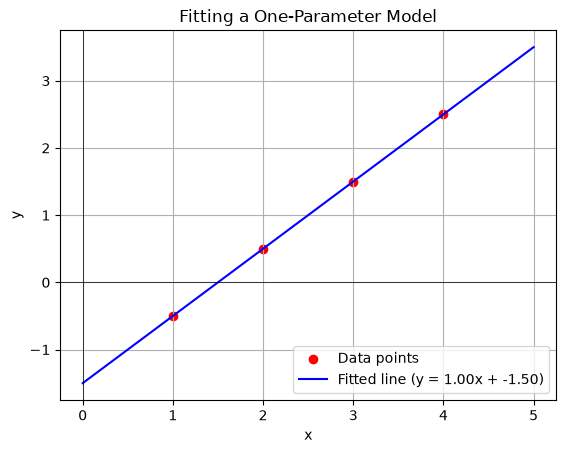

In [29]:
model = LinearModel(bias=True)
w, b = model.fit(xs, ys)

print(f"Fitted parameters: w = {w:.4f}, b = {b:.4f}")

# Plotting the resulting model
plt.scatter(xs.numpy(), ys.numpy(), color='red', label='Data points')

x_vals = torch.linspace(0, 5, 100).view(-1, 1)

plt.plot(x_vals.numpy(), model(x_vals).detach().numpy(), color='blue', label=f'Fitted line (y = {w:.2f}x + {b:.2f})')

plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend()
plt.grid()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Fitting a One-Parameter Model')
plt.show()

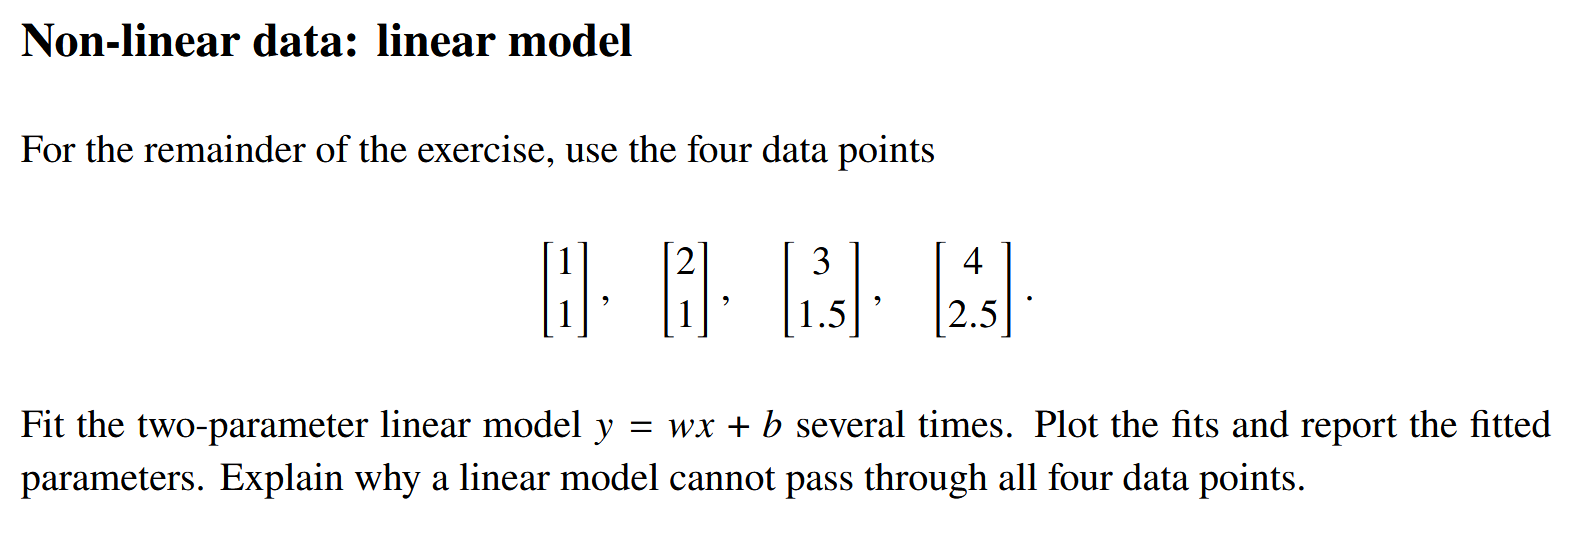

Fitted parameters: w = 0.5000, b = 0.2500


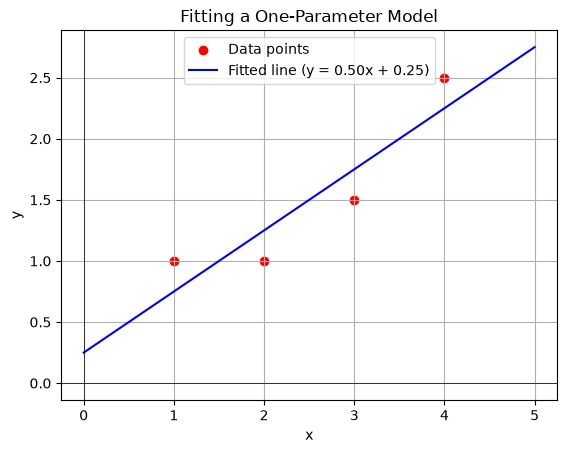

In [30]:
xs = torch.tensor([1.0, 2.0, 3.0, 4.0])
ys = torch.tensor([1.0, 1.0, 1.5, 2.5])

model = LinearModel(bias=True)
w, b = model.fit(xs, ys)

print(f"Fitted parameters: w = {w:.4f}, b = {b:.4f}")

# Plotting the resulting model
plt.scatter(xs.numpy(), ys.numpy(), color='red', label='Data points')

x_vals = torch.linspace(0, 5, 100).view(-1, 1)

plt.plot(x_vals.numpy(), model(x_vals).detach().numpy(), color='blue', label=f'Fitted line (y = {w:.2f}x + {b:.2f})')

plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend()
plt.grid()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Fitting a One-Parameter Model')
plt.show()

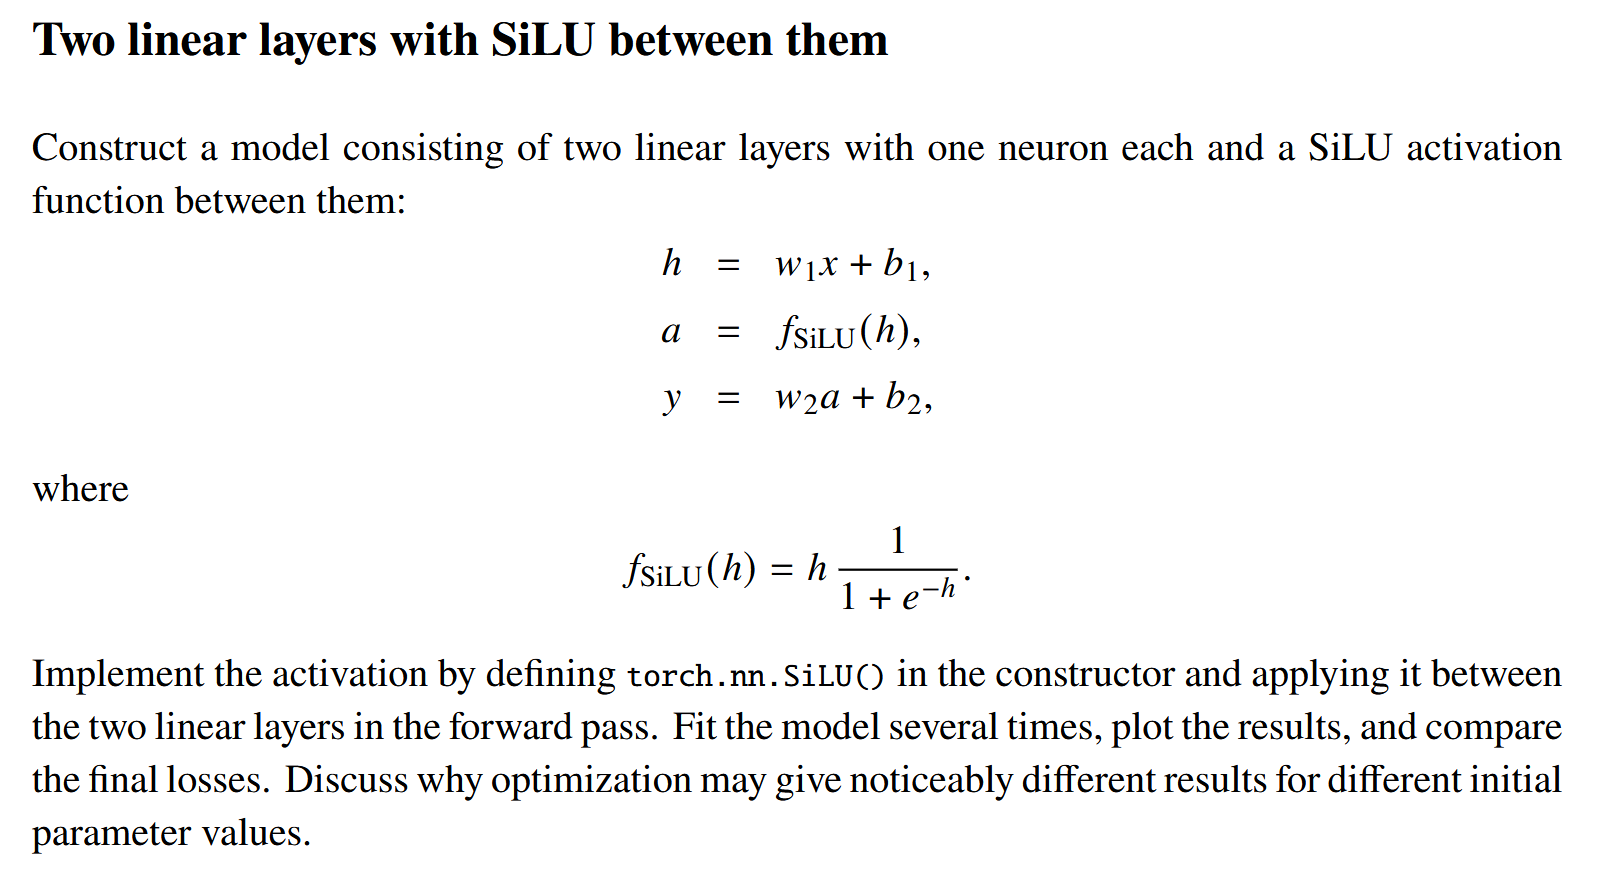

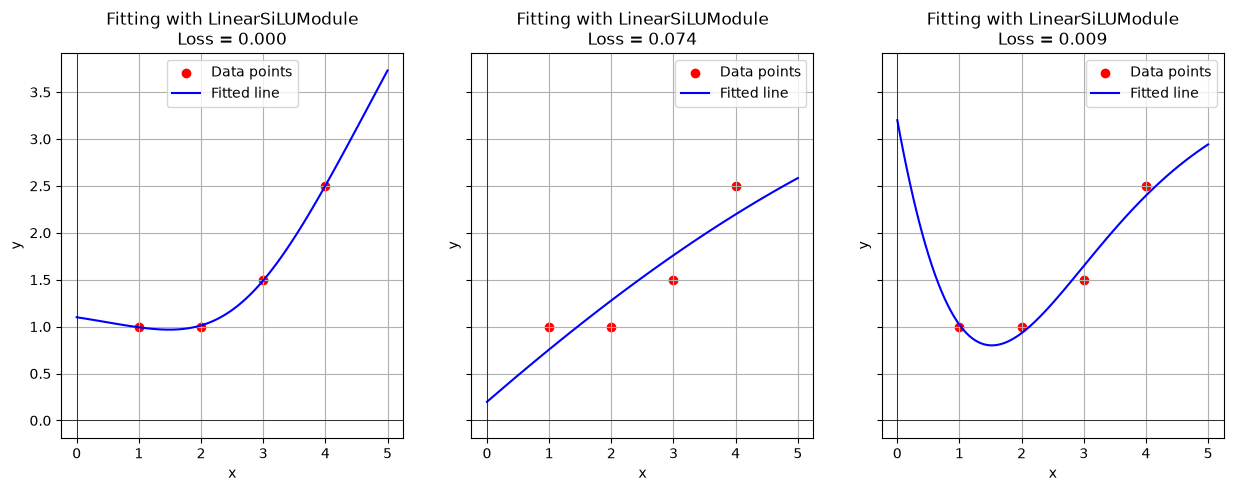

In [57]:
class LinearSiLUModule(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.layer1 = nn.Linear(1, 1)
        self.layer2 = nn.SiLU()
        self.layer3 = nn.Linear(1, 1)

        self.layers = [self.layer1, self.layer2, self.layer3]

        self.is_fitted = False

    def forward(self, x):
        x = x.view(-1, 1)
        for layer in self.layers:
            x = layer(x)
        return x.flatten()

    def fit(self, xs, ys, epochs=500, lr=0.1,
            lossFunction=nn.MSELoss, optimizer=optim.Adam):
        
        self.lossFunc = lossFunction()
        self.optimizer = optimizer(self.parameters(), lr=lr)

        for _ in range(epochs):
            self.optimizer.zero_grad()
            pred = self(xs)
            loss = self.lossFunc(pred, ys)
            loss.backward()
            self.optimizer.step()

        self.is_fitted = True
        return tuple(self.parameters())

    def plot(self, ax, xs, ys):
        if not self.is_fitted:
            raise RuntimeError("The model must be fitted before plotting.")

        # Plot original data points saved during fit()
        ax.scatter(xs.numpy(), ys.numpy(), color='red', label='Data points')

        x_vals = torch.linspace(0, 5, 100).view(-1, 1)
        y_preds = self(x_vals).detach().numpy()

        label = f'Fitted line'

        ax.plot(x_vals.numpy(), y_preds, color='blue', label=label)

        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.legend()
        ax.grid()
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.set_title(f'Fitting with {self._get_name()}')

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax in axes:
    model = LinearSiLUModule()
    params = model.fit(xs, ys)

    model.plot(ax, xs, ys)
    ax.set_title(ax.get_title() + f'\nLoss = {model.lossFunc(model(xs), ys):.3f}')

#plt.savefig('w10a_1.png')


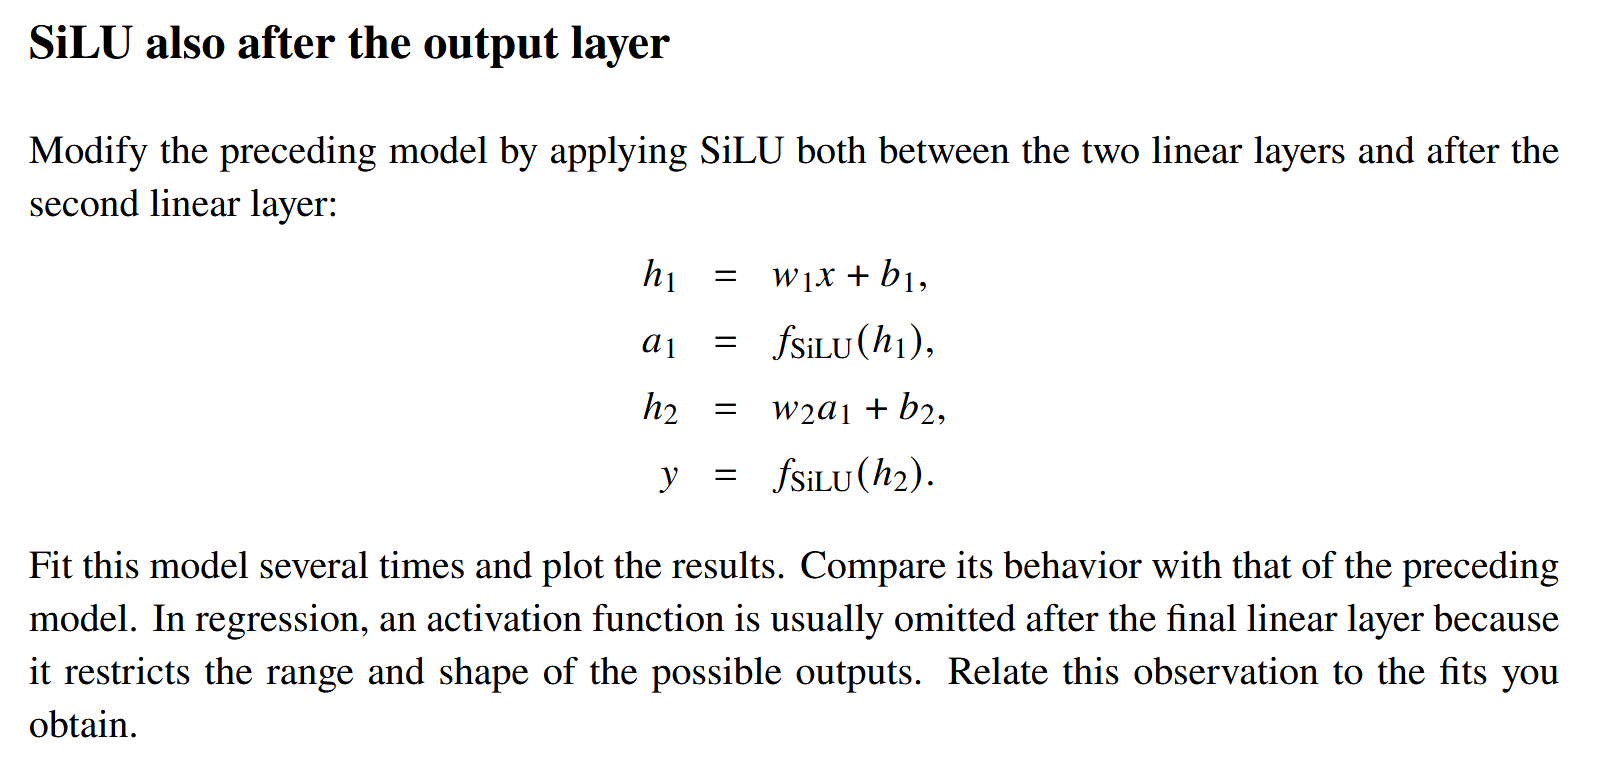
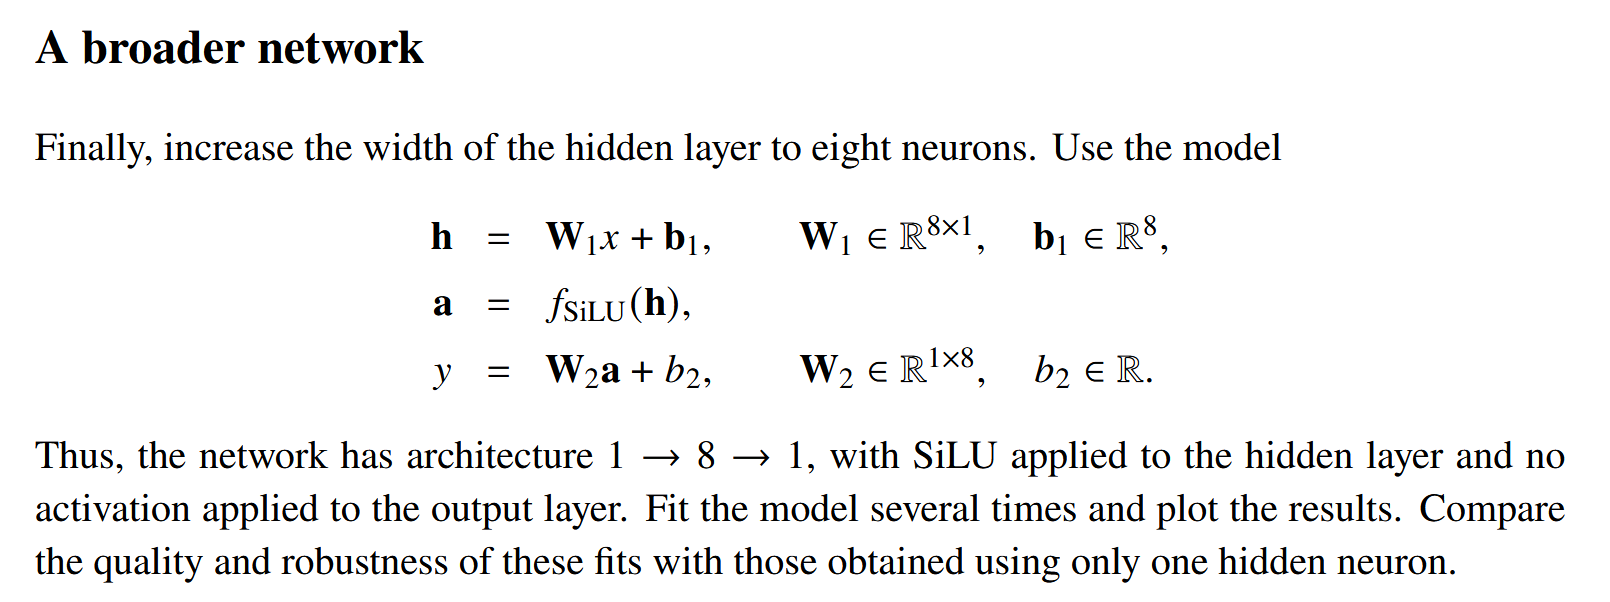

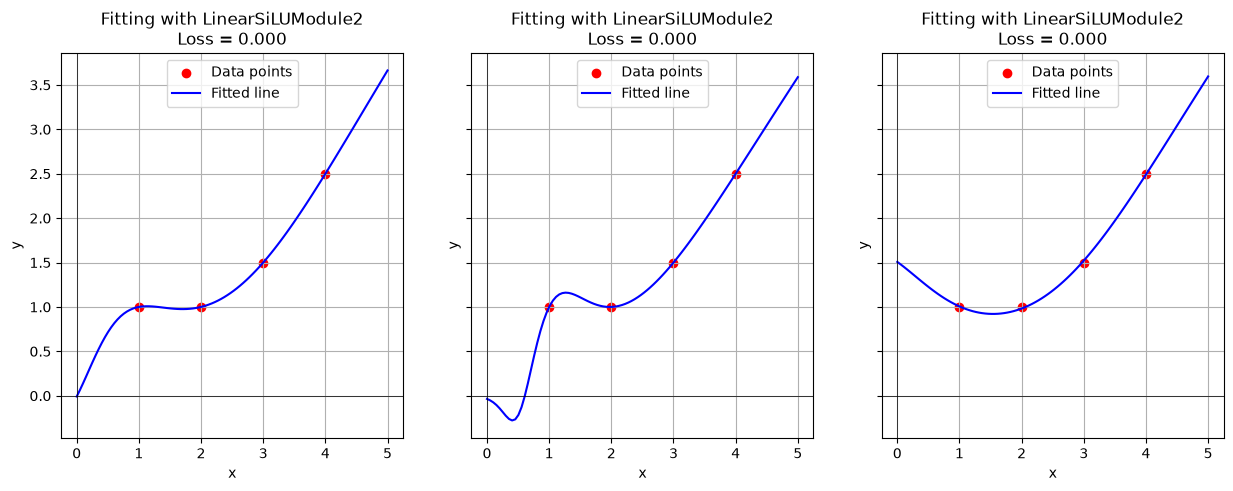

In [60]:
class LinearSiLUModule2(LinearSiLUModule):
    def __init__(self, *args, hidden = 8, **kwargs):
        super().__init__(*args, **kwargs)
        self.layer1 = nn.Linear(1, hidden)
        self.layer2 = nn.SiLU()
        self.layer3 = nn.Linear(hidden, 1)
        self.layer4 = nn.SiLU()

        self.layers = [self.layer1, self.layer2, self.layer3, self.layer4]

        
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax in axes:
    model = LinearSiLUModule2()
    params = model.fit(xs, ys)

    model.plot(ax, xs, ys)
    ax.set_title(ax.get_title() + f'\nLoss = {model.lossFunc(model(xs), ys):.3f}')
